# Lecture 16: Generative and Probabilistic Models for Science

A model trained with MSE predicts the **conditional mean** $\mathbb E[y \mid x]$. When the target is uncertain given the input, that mean is smooth and may not be a possible state. A **generative model** learns the distribution $p(y \mid x)$ and draws samples from it.

1. **A bimodal toy problem**: MSE regression and conditional diffusion.
2. **The forward process**: noising a Burgers field and which scales disappear first.
3. **Two moons**: reverse diffusion and flow matching, and the number of steps.
4. **Burgers from sparse sensors**: from 8 point values to the 128-point field, with an MSE model and a conditional diffusion model.
5. **Sensor values and sampling steps**: how well samples match the sensors, and how the spectrum depends on the number of sampling steps.

The models are trained checkpoints. Nothing trains in this notebook; the training code is at the end for offline runs (one HPC3 GPU).

In [1]:
import os
import math
import json
import urllib.request
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

torch.manual_seed(0)
torch.set_num_threads(4)

URL = "https://raw.githubusercontent.com/eecs-ml4sci/eecs-ml4sci.github.io/main/data/"
FILES = {"lecture12": ["burgers_train_128.npz"],
         "lecture16": ["toy.pt", "burgers_diff.pt", "burgers_mse.pt"]}
for folder, files in FILES.items():
    os.makedirs(f"../data/{folder}", exist_ok=True)
    for f in files:
        path = f"../data/{folder}/{f}"
        if not os.path.exists(path):
            print("downloading", folder, f)
            urllib.request.urlretrieve(URL + f"{folder}/{f}", path)
D12, D16 = "../data/lecture12/", "../data/lecture16/"
plt.rcParams.update({"font.size": 13, "axes.spines.top": False, "axes.spines.right": False})

### Diffusion schedule, samplers and networks

**Forward process.** With a noise schedule $\bar\alpha_t$ decreasing from 1 to 0 over $T = 1000$ steps (cosine schedule),

$$x_t = \sqrt{\bar\alpha_t}\,x_0 + \sqrt{1-\bar\alpha_t}\,\varepsilon, \qquad \varepsilon \sim \mathcal N(0, I).$$

**Training loss.** A network $\varepsilon_\theta(x_t, t)$ predicts the noise: $\mathcal L = \mathbb E\,\|\varepsilon - \varepsilon_\theta(x_t, t)\|^2$, with $t$ drawn at random.

**Sampler.** `sample` runs the reverse process on a subset of `steps` time steps. With `eta = 1`, it adds fresh noise in each step (as in DDPM). With `eta = 0`, it is the deterministic DDIM update. Each step: estimate the clean sample $\hat x_0 = (x_t - \sqrt{1-\bar\alpha_t}\,\varepsilon_\theta)/\sqrt{\bar\alpha_t}$, then move to the next noise level. Near $t = T$, $\bar\alpha_t \approx 0$ and the division by $\sqrt{\bar\alpha_t}$ amplifies small errors, so $\hat x_0$ is clipped to $[-6, 6]$ (the data lie well inside).

In [2]:
T_STEPS = 1000

def cosine_alpha_bar(T=T_STEPS, s=0.008):
    t = torch.arange(T + 1, dtype=torch.float64) / T
    f = torch.cos((t + s) / (1 + s) * math.pi / 2) ** 2
    ab = f / f[0]
    beta = (1 - ab[1:] / ab[:-1]).clamp(max=0.999)
    return torch.cumprod(1 - beta, 0).float()

ALPHA_BAR = cosine_alpha_bar()

def q_sample(x0, t, eps):
    ab = ALPHA_BAR[t].view(-1, *([1] * (x0.dim() - 1)))
    return ab.sqrt() * x0 + (1 - ab).sqrt() * eps

@torch.no_grad()
def sample(model, shape, cond=None, steps=100, eta=1.0, gen=None, return_path=False, clip=6.0):
    x = torch.randn(shape, generator=gen)
    ts = torch.linspace(T_STEPS - 1, 0, steps).round().long()
    path = [x.clone()]
    for i, t in enumerate(ts):
        ab = ALPHA_BAR[t]
        ab_prev = ALPHA_BAR[ts[i + 1]] if i + 1 < len(ts) else torch.tensor(1.0)
        tt = torch.full((shape[0],), int(t), dtype=torch.long)
        eps = model(x, tt, cond) if cond is not None else model(x, tt)
        x0 = (x - (1 - ab).sqrt() * eps) / ab.sqrt()
        if clip:                       # clip the clean-sample estimate; near t = T, 1/sqrt(alpha_bar) is huge
            x0 = x0.clamp(-clip, clip)
            eps = (x - ab.sqrt() * x0) / (1 - ab).sqrt()
        sigma = eta * ((1 - ab_prev) / (1 - ab) * (1 - ab / ab_prev)).clamp(min=0).sqrt()
        noise = torch.randn(shape, generator=gen) if i + 1 < len(ts) else torch.zeros(shape)
        x = ab_prev.sqrt() * x0 + (1 - ab_prev - sigma**2).clamp(min=0).sqrt() * eps + sigma * noise
        path.append(x.clone())
    return (x, torch.stack(path)) if return_path else x

def time_embedding(t, dim):
    half = dim // 2
    freqs = torch.exp(-math.log(10000) * torch.arange(half) / half)
    a = t.float()[:, None] * freqs[None]
    return torch.cat([a.sin(), a.cos()], 1)

class ToyMLP(nn.Module):
    # input: x_t (dx), optional condition (dc), sinusoidal embedding of t
    def __init__(self, dx=2, dc=0, width=256, depth=4, temb=64):
        super().__init__()
        self.temb = temb
        layers, d = [], dx + dc + temb
        for _ in range(depth):
            layers += [nn.Linear(d, width), nn.SiLU()]; d = width
        layers.append(nn.Linear(d, dx))
        self.net = nn.Sequential(*layers)
    def forward(self, x, t, c=None):
        h = [x, time_embedding(t, self.temb)]
        if c is not None: h.insert(1, c)
        return self.net(torch.cat(h, 1))

---
## Part 1: A bimodal toy problem

For $x \in [-1, 1]$, the target is $y = s\,(0.6 + 0.3\sin 3x) + 0.05\,\xi$, with $s = \pm 1$ at random and $\xi \sim \mathcal N(0, 1)$. For each $x$ there are two branches.

* **MSE model**: MLP with 2 hidden layers of 128 SiLU neurons, trained with MSE.
* **Conditional diffusion**: `ToyMLP` (3 hidden layers of 128) with inputs $(y_t, x, t)$, trained with the noise-prediction loss.

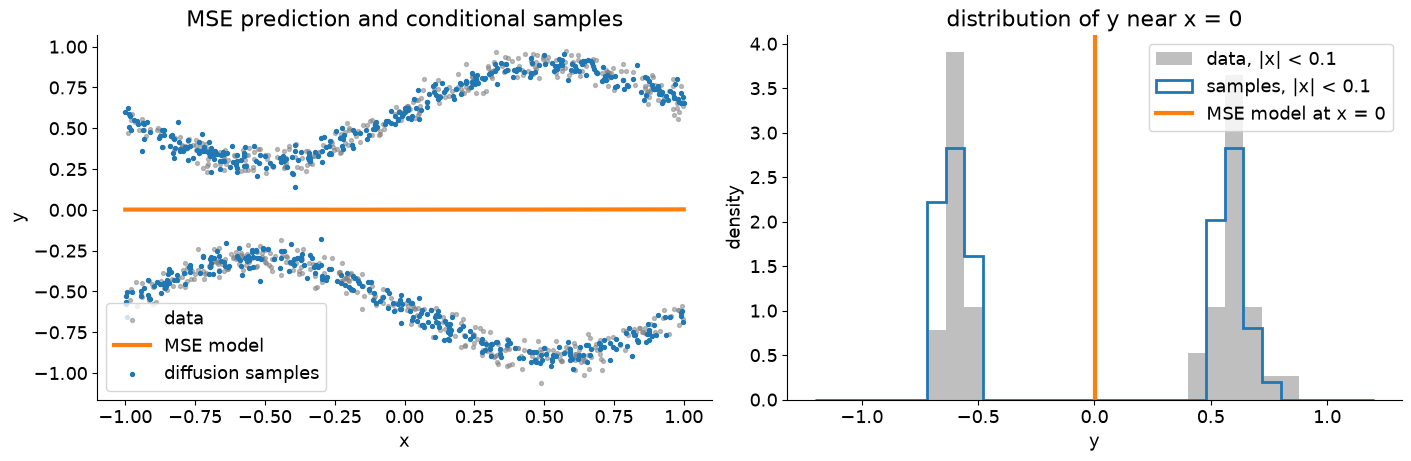

MSE of the MSE model: 0.404;  MSE of one sample per x: 0.799


In [3]:
def bimodal(n, gen=None):
    x = torch.rand(n, 1, generator=gen) * 2 - 1
    s = torch.randint(0, 2, (n, 1), generator=gen).float() * 2 - 1
    return x, s * (0.6 + 0.3 * torch.sin(3 * x)) + 0.05 * torch.randn(n, 1, generator=gen)

def moons(n, gen=None):
    t = torch.rand(n, generator=gen) * np.pi
    lab = torch.randint(0, 2, (n,), generator=gen)
    x = torch.where(lab == 0, torch.cos(t), 1 - torch.cos(t))
    y = torch.where(lab == 0, torch.sin(t), 0.5 - torch.sin(t))
    return torch.stack([x - 0.5, y - 0.25], 1) * 1.6 + 0.06 * torch.randn(n, 2, generator=gen)

ck = torch.load(D16 + "toy.pt")
mse_toy = nn.Sequential(nn.Linear(1, 128), nn.SiLU(), nn.Linear(128, 128), nn.SiLU(), nn.Linear(128, 1))
mse_toy.load_state_dict(ck["mse"])
cdiff = ToyMLP(dx=1, dc=1, width=128, depth=3); cdiff.load_state_dict(ck["cdiff"])
mdiff = ToyMLP(dx=2, width=256, depth=4); mdiff.load_state_dict(ck["mdiff"])
mfm = ToyMLP(dx=2, width=256, depth=4); mfm.load_state_dict(ck["mfm"])

g = torch.Generator().manual_seed(1)
xd, yd = bimodal(600, g)
xs = torch.linspace(-1, 1, 200)[:, None]
with torch.no_grad():
    ym = mse_toy(xs)
xc = torch.rand(600, 1, generator=g) * 2 - 1
yc = sample(cdiff, (600, 1), cond=xc, steps=100, gen=g)

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5), layout="constrained")
ax[0].scatter(xd, yd, s=8, color="gray", alpha=0.5, label="data")
ax[0].plot(xs, ym, color="C1", lw=3, label="MSE model")
ax[0].scatter(xc, yc, s=8, color="C0", label="diffusion samples")
ax[0].set(xlabel="x", ylabel="y", title="MSE prediction and conditional samples"); ax[0].legend()
mask = (xc.abs() < 0.1).squeeze()
ax[1].hist(yd[(xd.abs() < 0.1).squeeze()].numpy(), bins=30, range=(-1.2, 1.2), density=True, color="gray", alpha=0.5, label="data, |x| < 0.1")
ax[1].hist(yc[mask].numpy(), bins=30, range=(-1.2, 1.2), density=True, histtype="step", lw=2, color="C0", label="samples, |x| < 0.1")
ax[1].axvline(float(mse_toy(torch.zeros(1, 1)).detach()), color="C1", lw=3, label="MSE model at x = 0")
ax[1].set(xlabel="y", ylabel="density", title="distribution of y near x = 0"); ax[1].legend()
plt.show()
print(f"MSE of the MSE model: {F.mse_loss(mse_toy(xd), yd):.3f};  MSE of one sample per x: {F.mse_loss(sample(cdiff, (600, 1), cond=xd, gen=g), yd):.3f}")

**What to observe**

* The MSE model predicts $y \approx 0$ for all $x$: the mean of the two branches, where there are no data.
* The diffusion samples fall on both branches, about half on each, with the spread of the data. The histogram near $x = 0$ shows two peaks for data and samples.
* The MSE model has the lower MSE. One sample per input has about twice the MSE of the mean: a sample on the wrong branch is penalized heavily. MSE alone cannot tell which model describes the data.

---
## Part 2: The forward process on a Burgers field

A Burgers field from the Lecture 12 data ($\nu = 0.01$, periodic, 128 points, $t = 0.3$), scaled by $1/0.5$ as in training. We add noise at several steps $t$ and compare the power spectrum of the signal, $\bar\alpha_t\,|\hat x_0(k)|^2$, with that of the noise, $(1 - \bar\alpha_t)/N$ per mode.

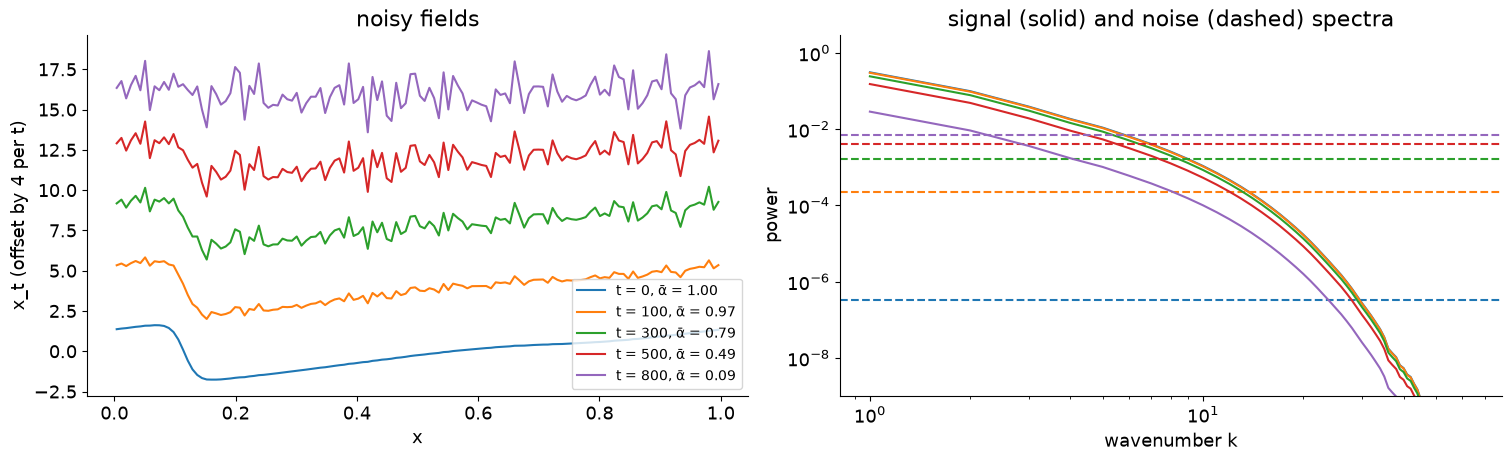

t = 100: modes above the noise: k <= 13
t = 300: modes above the noise: k <= 8
t = 500: modes above the noise: k <= 5
t = 800: modes above the noise: k <= 2


In [4]:
u = np.load(D12 + "burgers_train_128.npz")["u"].astype(np.float32)
SC = 0.5
x0 = torch.tensor(u[950, 15]) / SC
xg = (np.arange(128) + 0.5) / 128
eps = torch.randn(128, generator=torch.Generator().manual_seed(3))
spec = lambda v: (np.abs(np.fft.rfft(np.asarray(v), axis=-1)) ** 2 / 128**2)[..., 1:]
k = np.arange(1, 65)

fig, ax = plt.subplots(1, 2, figsize=(15, 4.5), layout="constrained")
for j, t in enumerate([0, 100, 300, 500, 800]):
    ab = float(ALPHA_BAR[t])
    xt = math.sqrt(ab) * x0 + math.sqrt(1 - ab) * eps
    ax[0].plot(xg, xt + 4 * j, color=f"C{j}", label=f"t = {t}, ᾱ = {ab:.2f}")
    ax[1].loglog(k, ab * spec(x0), color=f"C{j}")
    ax[1].axhline((1 - ab) / 128, color=f"C{j}", ls="--")
ax[0].set(xlabel="x", ylabel="x_t (offset by 4 per t)", title="noisy fields"); ax[0].legend(fontsize=10)
ax[1].set(xlabel="wavenumber k", ylabel="power", ylim=(1e-9, 3), title="signal (solid) and noise (dashed) spectra")
plt.show()
for t in [100, 300, 500, 800]:
    ab = float(ALPHA_BAR[t]); above = k[ab * spec(x0) > (1 - ab) / 128]
    print(f"t = {t}: modes above the noise: k <= {above.max() if len(above) else 0}")

**What to observe**

* The noise has a flat spectrum. The Burgers spectrum falls with $k$, so the high wavenumbers drop below the noise first.
* As $t$ grows, the highest wavenumber above the noise decreases. At $t = 800$ only the largest scales are left.
* The reverse process therefore generates the large-scale shape first and the fronts last.

---
## Part 3: Two moons: reverse diffusion and flow matching

Both models are `ToyMLP` networks (4 hidden layers of 256) trained on 2D points.

* **Diffusion**: noise-prediction loss, sampled with `sample`.
* **Flow matching**: a velocity field $v_\theta(x, s)$ trained on straight paths $x_s = (1-s)\,z + s\,x_1$ with target velocity $x_1 - z$. We sample by integrating $dx/ds = v_\theta$ with Euler steps from $s = 0$ to 1.

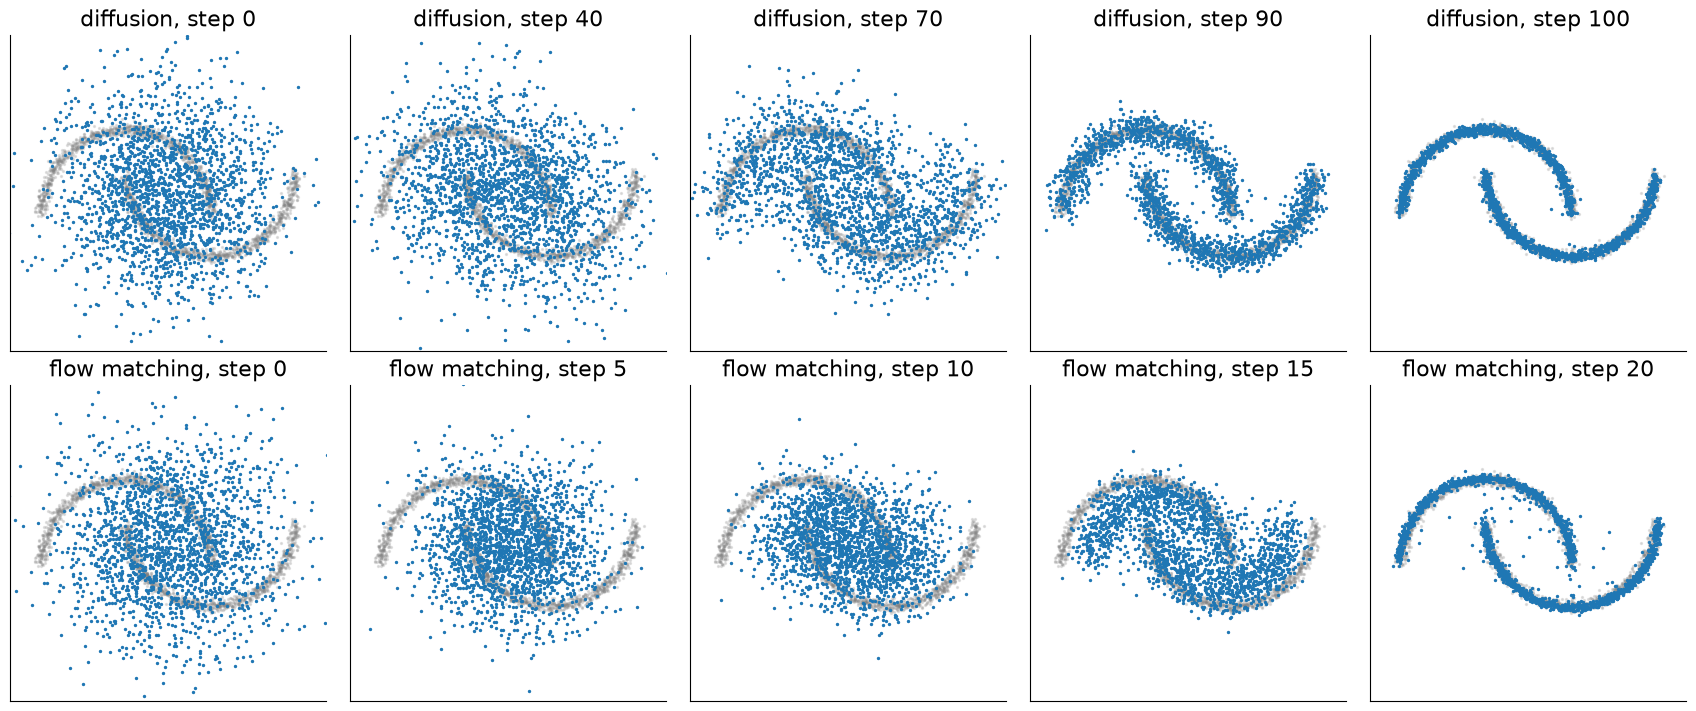

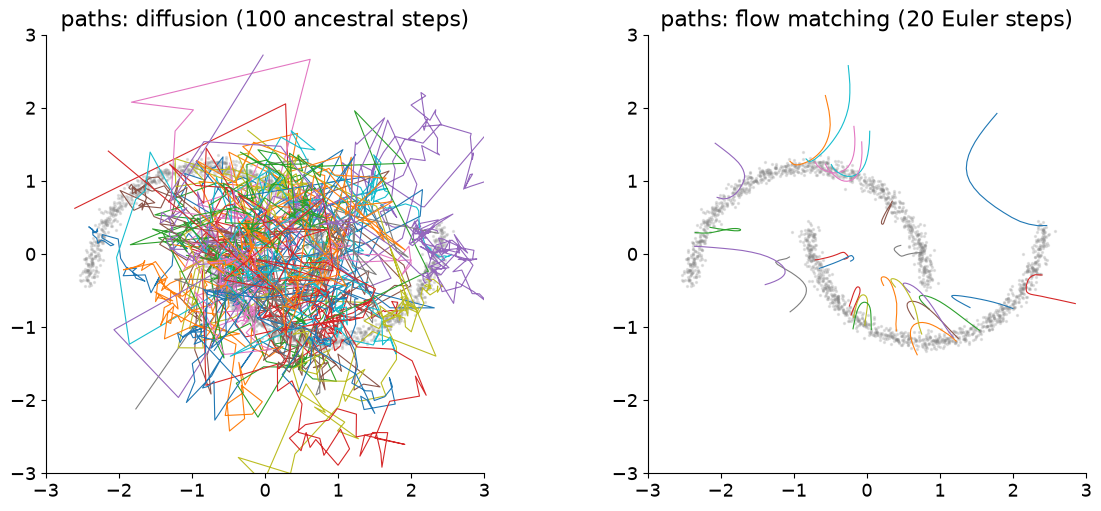

In [5]:
@torch.no_grad()
def fm_sample(model, z, n_steps):
    x, path = z.clone(), [z.clone()]
    for i in range(n_steps):
        s = torch.full((len(x),), (i + 0.5) / n_steps)
        x = x + model(x, s * 1000) / n_steps
        path.append(x.clone())
    return x, torch.stack(path)

g = torch.Generator().manual_seed(2)
data = moons(2000, g)
z = torch.randn(2000, 2, generator=g)
_, pd = sample(mdiff, (2000, 2), steps=100, gen=torch.Generator().manual_seed(4), return_path=True)
_, pf = fm_sample(mfm, z, 20)

fig, ax = plt.subplots(2, 5, figsize=(17, 7), layout="constrained")
for row, (P, name, idx) in enumerate([(pd, "diffusion, step", [0, 40, 70, 90, 100]), (pf, "flow matching, step", [0, 5, 10, 15, 20])]):
    for a, i in zip(ax[row], idx):
        a.scatter(data[:, 0], data[:, 1], s=2, color="gray", alpha=0.2)
        a.scatter(P[i, :, 0], P[i, :, 1], s=2, color="C0")
        a.set(xlim=(-3, 3), ylim=(-3, 3), aspect="equal", xticks=[], yticks=[], title=f"{name} {i}")
plt.show()

fig, ax = plt.subplots(1, 2, figsize=(12, 5), layout="constrained")
for a, (P, name) in zip(ax, [(pd, "diffusion (100 ancestral steps)"), (pf, "flow matching (20 Euler steps)")]):
    a.scatter(data[:, 0], data[:, 1], s=2, color="gray", alpha=0.2)
    for j in range(25):
        a.plot(P[:, j, 0], P[:, j, 1], lw=0.8)
    a.set(xlim=(-3, 3), ylim=(-3, 3), aspect="equal", title=f"paths: {name}")
plt.show()

**What to observe**

* In both models the cloud of points changes little in the first steps. The two moons appear in the second half.
* Diffusion paths are jagged: each step adds fresh noise. Flow matching paths are smooth: the model is an ODE trained on straight paths, and the paths bend only near the data.

### Sample quality against the number of steps

We measure the distance between the samples and the data with the energy distance $2\,\mathbb E\|X - Y\| - \mathbb E\|X - X'\| - \mathbb E\|Y - Y'\|$ ($X$: samples, $Y$: data); zero when the distributions are equal. Diffusion uses the deterministic DDIM sampler (`eta = 0`) at each step count.

In [6]:
def energy_distance(a, b):
    d = lambda p, q: torch.cdist(p, q).mean()
    return float(2 * d(a, b) - d(a, a) - d(b, b))

ref = moons(2000, torch.Generator().manual_seed(9))
print(f"data vs data: {energy_distance(moons(2000, torch.Generator().manual_seed(10)), ref):.4f}")
for n in [2, 5, 10, 20, 50]:
    sd = sample(mdiff, (2000, 2), steps=n, eta=0.0, gen=torch.Generator().manual_seed(1))
    sf, _ = fm_sample(mfm, torch.randn(2000, 2, generator=torch.Generator().manual_seed(1)), n)
    print(f"{n:3d} steps   diffusion (DDIM): {energy_distance(sd, ref):.4f}   flow matching (Euler): {energy_distance(sf, ref):.4f}")

data vs data: 0.0006
  2 steps   diffusion (DDIM): 5.2390   flow matching (Euler): 0.0335
  5 steps   diffusion (DDIM): 0.3546   flow matching (Euler): 0.0099
 10 steps   diffusion (DDIM): 0.1852   flow matching (Euler): 0.0047
 20 steps   diffusion (DDIM): 0.0660   flow matching (Euler): 0.0030
 50 steps   diffusion (DDIM): 0.0101   flow matching (Euler): 0.0027


 50 steps   diffusion (DDIM): 0.0101   flow matching (Euler): 0.0027


**What to observe**

* Both models approach the data-to-data level as the number of steps grows.
* With few steps, flow matching is closer to the data: its paths are straighter, so Euler steps results in a smaller error. The exact numbers vary with the seed and training but the trend agrees with Lipman et al. (2023).

---
## Part 4: Burgers from sparse sensors

Lecture 12 Burgers data ($\nu = 0.01$, periodic $[0, 1)$, 128 points), times $t \ge 0.1$. Trajectories 0–899 for training, 900–999 for testing. The **condition** $c$ is $u$ at 8 sensors, one every 16 points, interpolated linearly (periodic) to all 128 points. The **target** $y$ is the 128-point field.

Both models are the same periodic 1D U-Net (3 levels with 32, 64 and 96 channels, two residual blocks per level, GroupNorm, SiLU, sinusoidal time embedding). Inputs: a field channel and the condition channel.

* **MSE model**: the field channel is zero and $t = 0$ and trained with MSE on $y$ (4000 iterations).
* **Diffusion model**: the field channel is $y_t$ and trained with the noise-prediction loss (8000 iterations). Sampled with 100 ancestral steps.

Both: Adam with a one-cycle schedule, batch 64, augmentation with periodic shifts and the Burgers symmetry $u(x) \to -u(-x)$ (Lecture 5).

In [7]:
class PConv(nn.Conv1d):
    def forward(self, x):
        p = self.kernel_size[0] // 2
        return super().forward(F.pad(x, (p, p), mode="circular"))

class ResBlock(nn.Module):
    def __init__(self, ci, co, temb):
        super().__init__()
        self.n1, self.c1 = nn.GroupNorm(8, ci), PConv(ci, co, 3)
        self.t = nn.Linear(temb, co)
        self.n2, self.c2 = nn.GroupNorm(8, co), PConv(co, co, 3)
        self.skip = nn.Conv1d(ci, co, 1) if ci != co else nn.Identity()
    def forward(self, x, e):
        h = self.c1(F.silu(self.n1(x))) + self.t(e)[:, :, None]
        return self.c2(F.silu(self.n2(h))) + self.skip(x)

class UNet1d(nn.Module):
    def __init__(self, cin=2, ch=(32, 64, 96), temb=128):
        super().__init__()
        self.temb = temb
        self.emb = nn.Sequential(nn.Linear(temb, temb), nn.SiLU(), nn.Linear(temb, temb))
        self.inp = PConv(cin, ch[0], 3)
        self.down, c, skips = nn.ModuleList(), ch[0], [ch[0]]
        for co in ch:
            self.down.append(nn.ModuleList([ResBlock(c, co, temb), ResBlock(co, co, temb)])); c = co; skips.append(c)
        self.mid = nn.ModuleList([ResBlock(c, c, temb), ResBlock(c, c, temb)])
        self.up = nn.ModuleList()
        for co in reversed(ch):
            s = skips.pop()
            self.up.append(nn.ModuleList([ResBlock(c + s, co, temb), ResBlock(co, co, temb)])); c = co
        self.out = nn.Sequential(nn.GroupNorm(8, c), nn.SiLU(), PConv(c, 1, 3))
        self.nlev = len(ch)
    def forward(self, x, t, cond):
        e = self.emb(time_embedding(t, self.temb))
        h = self.inp(torch.cat([x, cond], 1)); hs = [h]
        for i, (b1, b2) in enumerate(self.down):
            h = b2(b1(h, e), e); hs.append(h)
            if i < self.nlev - 1: h = F.avg_pool1d(h, 2)
        for b in self.mid: h = b(h, e)
        for b1, b2 in self.up:
            s = hs.pop()
            if h.shape[-1] != s.shape[-1]: h = F.interpolate(h, size=s.shape[-1], mode="nearest")
            h = b2(b1(torch.cat([h, s], 1), e), e)
        return self.out(h)

STRIDE = 16

def cond_of(y, stride=STRIDE):
    # u at every stride-th point, linearly interpolated (periodic) to all points
    s = y[..., ::stride]; nxt = torch.roll(s, -1, -1)
    w = (torch.arange(y.shape[-1]) % stride).float() / stride
    return s.repeat_interleave(stride, -1) * (1 - w) + nxt.repeat_interleave(stride, -1) * w

def load_unet(name):
    m = UNet1d(); m.load_state_dict(torch.load(D16 + name + ".pt")["state_dict"]); return m.eval()

diff, mse = load_unet("burgers_diff"), load_unet("burgers_mse")

@torch.no_grad()
def mse_pred(y):
    return mse(torch.zeros_like(y), torch.zeros(len(y), dtype=torch.long), cond_of(y))

def sr_samples(y, n, seed=0):
    c = cond_of(y).repeat(n, 1, 1)
    return sample(diff, c.shape, cond=c, steps=100, gen=torch.Generator().manual_seed(seed)).view(n, *y.shape)

test = torch.tensor(u[900:, 5:]).reshape(-1, 128) / SC
print("test fields:", tuple(test.shape))

test fields: (4600, 128)


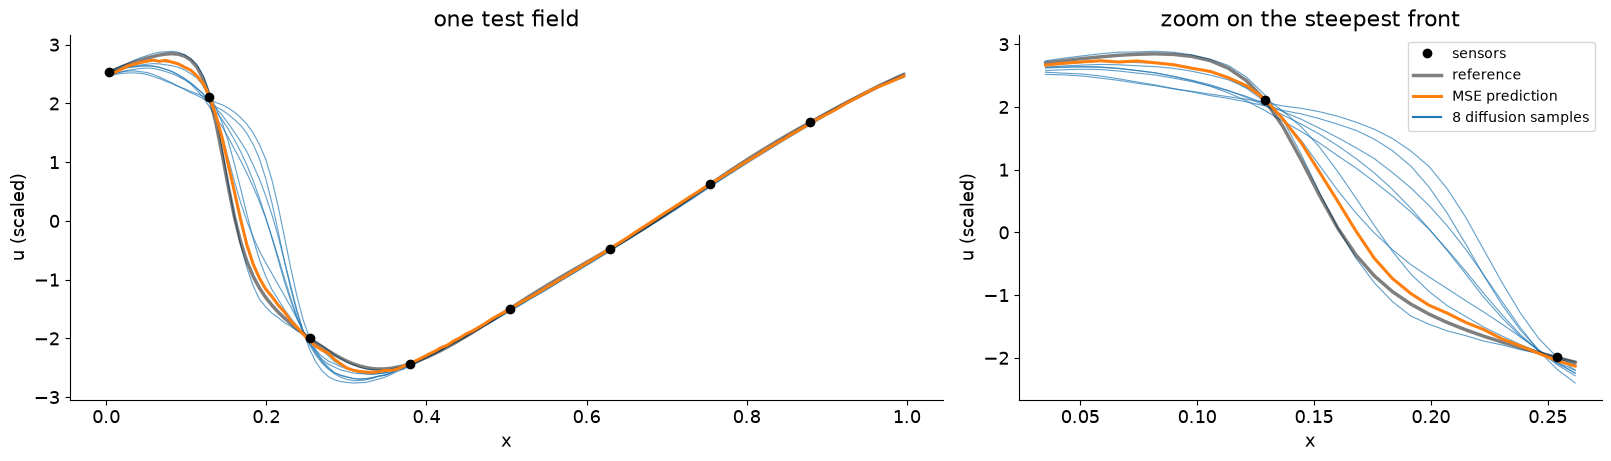

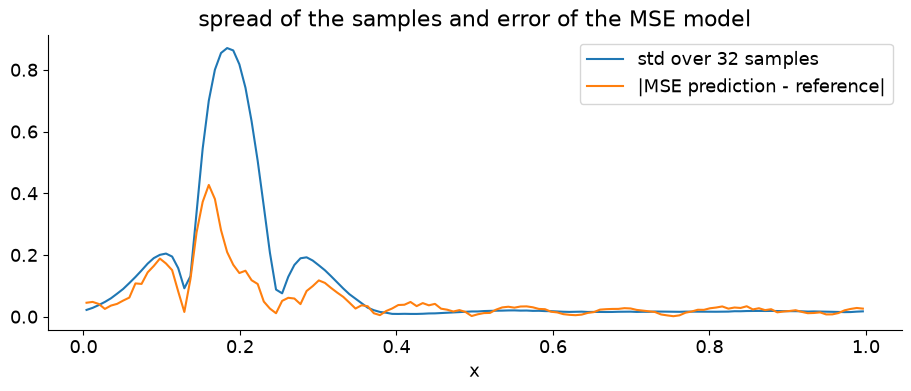

correlation between spread and MSE error along x: 0.81


In [8]:
y0 = test[1840][None, None]                                     # trajectory 940, t = 0.1: a front between two sensors
S = sr_samples(y0, 32, seed=1)[:, 0, 0].numpy()
yt, ym, cb = y0[0, 0].numpy(), mse_pred(y0)[0, 0].numpy(), cond_of(y0)[0, 0].numpy()
xf = int(np.argmax(np.abs(np.roll(yt, -1) - yt))); lo, hi = max(xf - 14, 0), min(xf + 16, 128)

fig, ax = plt.subplots(1, 2, figsize=(16, 4.5), layout="constrained", gridspec_kw={"width_ratios": [1.5, 1]})
for a, sl in [(ax[0], slice(0, 128)), (ax[1], slice(lo, hi))]:
    sp = [j for j in range(0, 128, STRIDE) if sl.start <= j < sl.stop]
    a.plot(xg[sp], yt[sp], "ko", ms=6, label="sensors", zorder=5)
    for s in S[:8]:
        a.plot(xg[sl], s[sl], color="C0", lw=0.8, alpha=0.7)
    a.plot(xg[sl], yt[sl], color="k", lw=2.5, alpha=0.5, label="reference")
    a.plot(xg[sl], ym[sl], color="C1", lw=2.2, label="MSE prediction")
    a.set(xlabel="x", ylabel="u (scaled)")
ax[1].plot([], [], color="C0", label="8 diffusion samples"); ax[1].legend(fontsize=10)
ax[0].set_title("one test field"); ax[1].set_title("zoom on the steepest front")
plt.show()

std, err = S.std(0), np.abs(ym - yt)
fig, ax = plt.subplots(figsize=(9, 3.8), layout="constrained")
ax.plot(xg, std, label="std over 32 samples"); ax.plot(xg, err, label="|MSE prediction - reference|")
ax.set(xlabel="x", title="spread of the samples and error of the MSE model"); ax.legend(); plt.show()
print(f"correlation between spread and MSE error along x: {np.corrcoef(std, err)[0, 1]:.2f}")

**What to observe**

* On the ramps, the samples, the MSE prediction and the reference agree: the sensors determine the field there.
* Between the two sensors around the front, the samples differ in the position and steepness of the front. The reference is one of these possibilities. The MSE prediction lies close to the reference.
* The spread of the samples is largest where the MSE error is largest. The model gives an uncertainty estimate without being trained for one; whether it has the right size is the subject of Lecture 17.

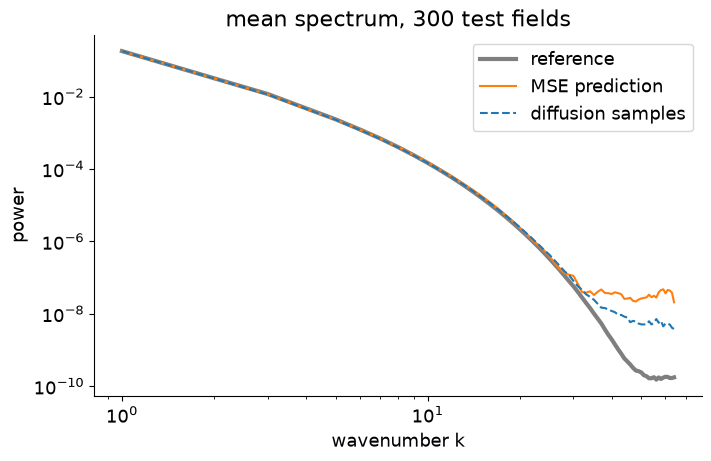

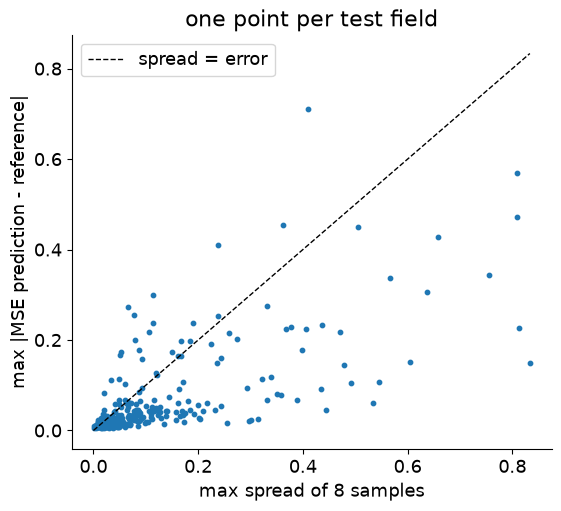

correlation over fields: 0.70;  fraction of fields with spread > error: 0.78
steepest jump relative to the reference: MSE 1.023, sample 1.008
relative L2 error, MSE prediction:            0.0378
relative L2 error, one diffusion sample:      0.0981
relative L2 error, mean of 8 samples:         0.0691


In [9]:
torch.manual_seed(0)
sel = torch.randperm(len(test))[:300]
Y = test[sel][:, None]
M = mse_pred(Y)[:, 0].numpy()
Sm = sr_samples(Y, 2, seed=5)[:, :, 0].numpy()                  # 2 samples per field
Yn = Y[:, 0].numpy()
S8 = sr_samples(Y[:100], 8, seed=7)[:, :, 0].numpy()           # 8 samples for 100 fields
rel = lambda a, b: np.sqrt(((a - b) ** 2).mean()) / np.sqrt((b ** 2).mean())

fig, ax = plt.subplots(figsize=(7, 4.5), layout="constrained")
ax.loglog(k, spec(Yn).mean(0), "k", lw=3, alpha=0.5, label="reference")
ax.loglog(k, spec(M).mean(0), "C1", label="MSE prediction")
ax.loglog(k, spec(Sm.reshape(-1, 128)).mean(0), "C0--", label="diffusion samples")
ax.set(xlabel="wavenumber k", ylabel="power", title="mean spectrum, 300 test fields"); ax.legend(); plt.show()

S300 = sr_samples(Y, 8, seed=11)[:, :, 0].numpy()
spread, err_max = S300.std(0).max(-1), np.abs(M - Yn).max(-1)
fig, ax = plt.subplots(figsize=(5.5, 5), layout="constrained")
ax.scatter(spread, err_max, s=10); lim = max(spread.max(), err_max.max())
ax.plot([0, lim], [0, lim], "k--", lw=1, label="spread = error")
ax.set(xlabel="max spread of 8 samples", ylabel="max |MSE prediction - reference|", title="one point per test field"); ax.legend(); plt.show()
print(f"correlation over fields: {np.corrcoef(spread, err_max)[0, 1]:.2f};  fraction of fields with spread > error: {(spread > err_max).mean():.2f}")
sharp = lambda v: np.abs(np.roll(v, -1, -1) - v).max(-1)
print(f"steepest jump relative to the reference: MSE {np.mean(sharp(M) / sharp(Yn)):.3f}, sample {np.mean(sharp(Sm[0]) / sharp(Yn)):.3f}")

print(f"relative L2 error, MSE prediction:            {rel(M[:100], Yn[:100]):.4f}")
print(f"relative L2 error, one diffusion sample:      {rel(S8[0], Yn[:100]):.4f}")
print(f"relative L2 error, mean of 8 samples:         {rel(S8.mean(0), Yn[:100]):.4f}")

**What to observe**

* The mean spectra of the reference, the MSE prediction and the samples agree up to $k \approx 25$. Beyond that, both models add a little noise at very low power. The steepest jump of the MSE prediction is as large as the reference's on average: with 8 sensors most fields are nearly determined, so the MSE model blurs little.
* A single sample has a larger pointwise error than the MSE prediction. The mean of 8 samples is in between: the sample mean estimates $\mathbb E[y \mid c]$, the quantity the MSE model learns, and approaches it as the number of samples grows.
* Fields with a large spread are the fields where the MSE prediction is wrong. The spread is often larger than the error: it marks the uncertain fields, and its size needs a calibration check (Lecture 17).
* A generative model pays off when the target is strongly uncertain given the input. Exercise 2 makes this problem harder.

---
## Part 5: Sensor values and the number of sampling steps

A sample should pass through the observed values. The models learn this from data, so it holds approximately (a soft constraint). We compare the error at the sensor points with the error elsewhere.

Then we sample with fewer steps (DDPM and deterministic DDIM) and look at the high-wavenumber end of the spectrum.

relative error at the sensors:     MSE 0.0111   sample 0.0194
relative error between sensors:    MSE 0.0443   sample 0.1022


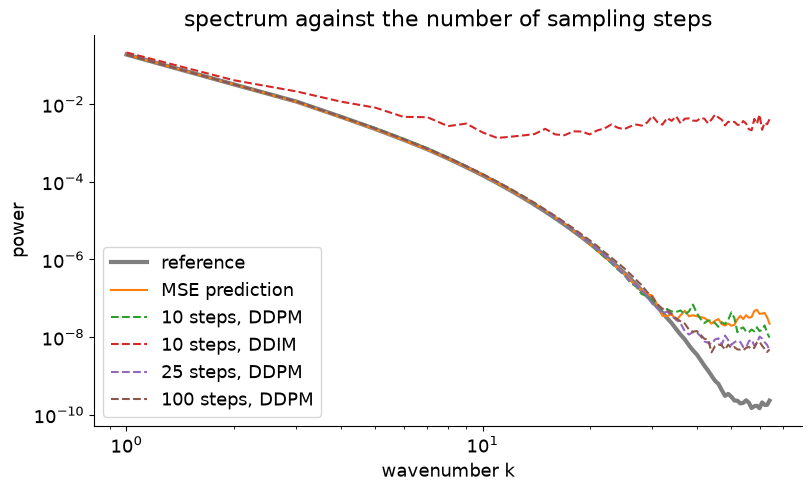

In [10]:
on = np.zeros(128, bool); on[::STRIDE] = True
err_at = lambda P, m: rel(P[:, m], Yn[:, m])
print(f"relative error at the sensors:     MSE {err_at(M, on):.4f}   sample {err_at(Sm[0], on):.4f}")
print(f"relative error between sensors:    MSE {err_at(M, ~on):.4f}   sample {err_at(Sm[0], ~on):.4f}")

Y50 = Y[:100]
fig, ax = plt.subplots(figsize=(8, 4.8), layout="constrained")
ax.loglog(k, spec(Y50[:, 0].numpy()).mean(0), "k", lw=3, alpha=0.5, label="reference")
ax.loglog(k, spec(M[:100]).mean(0), "C1", label="MSE prediction")
c = cond_of(Y50)
for j, (n, eta) in enumerate([(10, 1.0), (10, 0.0), (25, 1.0), (100, 1.0)]):
    P = sample(diff, c.shape, cond=c, steps=n, eta=eta, gen=torch.Generator().manual_seed(3))[:, 0].numpy()
    ax.loglog(k, spec(P).mean(0), color=f"C{j+2}", ls="--", label=f"{n} steps, {'DDPM' if eta else 'DDIM'}")
ax.set(xlabel="wavenumber k", ylabel="power", title="spectrum against the number of sampling steps"); ax.legend(); plt.show()

**What to observe**

* At the sensor points both models are close to the observed values, and much closer than between sensors. The values are not exact: nothing in the models enforces them.
* With 25 or 100 ancestral (DDPM) steps the spectra agree with each other and with the reference up to $k \approx 30$. Here 10 steps are already close.
* 10 deterministic DDIM steps leave a large amount of noise at all wavenumbers above $k \approx 5$: for this model and schedule, DDIM needs more steps. On the two moons (Part 3), DDIM also needed about 50 steps.
* The cost of a sample is proportional to the number of steps. Few-step samplers, distillation and flow matching all aim to reduce this cost.

---
## Exercises

1. **Calibration preview.** For 100 test fields, compute the spread of 8 samples (std averaged over $x$) and the error of their mean. Plot one against the other. Is the spread too small, too large, or about right?
2. **Fewer sensors.** Train both models with a sensor every 32 points (`train_burgers(kind, stride=32)` below). How do the spread of the samples and the gap between the spectra change?
3. **A residual model (CorrDiff).** Train a diffusion model on the residual $y - \mu(c)$, with $\mu$ the MSE model. Compare its samples and spectrum with Part 4 at the same number of training iterations.
4. **Flow matching for Burgers.** Replace the noise-prediction loss with the flow matching loss and the sampler with Euler steps. Compare the spectrum at 10 and 50 steps.

In [11]:
# Training code (used for the checkpoints; run offline, e.g. on one HPC3 GPU)

def train_toy(steps=(4000, 15000, 20000, 20000), B=512, seed=0):
    torch.manual_seed(seed)
    def fit(model, loss_fn, n, lr=1e-3):
        opt = torch.optim.Adam(model.parameters(), lr=lr); sch = torch.optim.lr_scheduler.CosineAnnealingLR(opt, n)
        for _ in range(n):
            loss = loss_fn(); opt.zero_grad(); loss.backward(); opt.step(); sch.step()
        return model
    mse = nn.Sequential(nn.Linear(1, 128), nn.SiLU(), nn.Linear(128, 128), nn.SiLU(), nn.Linear(128, 1))
    def l_mse():
        x, y = bimodal(B); return F.mse_loss(mse(x), y)
    cd = ToyMLP(dx=1, dc=1, width=128, depth=3)
    def l_cd():
        x, y = bimodal(B); t = torch.randint(0, T_STEPS, (B,)); e = torch.randn_like(y)
        return F.mse_loss(cd(q_sample(y, t, e), t, x), e)
    md_ = ToyMLP(dx=2, width=256, depth=4)
    def l_md():
        x0 = moons(B); t = torch.randint(0, T_STEPS, (B,)); e = torch.randn_like(x0)
        return F.mse_loss(md_(q_sample(x0, t, e), t), e)
    fm = ToyMLP(dx=2, width=256, depth=4)
    def l_fm():
        x1 = moons(B); z = torch.randn_like(x1); s = torch.rand(B, 1)
        return F.mse_loss(fm((1 - s) * z + s * x1, s[:, 0] * 1000), x1 - z)
    for m, l, n in zip([mse, cd, md_, fm], [l_mse, l_cd, l_md, l_fm], steps):
        fit(m, l, n)
    torch.save({"mse": mse.state_dict(), "cdiff": cd.state_dict(), "mdiff": md_.state_dict(), "mfm": fm.state_dict()}, "toy.pt")

def train_burgers(kind="diff", steps=8000, stride=STRIDE, B=64, seed=0, device="cpu"):
    # kind: "diff" (noise prediction, 8000 iterations) or "mse" (4000 iterations)
    import copy
    torch.manual_seed(seed)
    utr = (torch.tensor(u[:900, 5:]).reshape(-1, 128) / SC).to(device)
    model = UNet1d().to(device); ema = copy.deepcopy(model)
    lr = 2e-4 if kind == "diff" else 1e-3
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0)
    sch = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=steps, pct_start=0.03)
    ab = ALPHA_BAR.to(device)
    for it in range(steps):
        x0 = utr[torch.randint(0, len(utr), (B,), device=device)][:, None]
        x0 = torch.roll(x0, int(torch.randint(0, 128, ())), -1)
        if torch.rand(()) < 0.5:
            x0 = -torch.flip(x0, [-1])
        c = cond_of(x0, stride)
        if kind == "diff":
            t = torch.randint(0, T_STEPS, (B,), device=device); e = torch.randn_like(x0)
            a = ab[t].view(-1, 1, 1)
            loss = F.mse_loss(model(a.sqrt() * x0 + (1 - a).sqrt() * e, t, c), e)
        else:
            loss = F.mse_loss(model(torch.zeros_like(x0), torch.zeros(B, dtype=torch.long, device=device), c), x0)
        opt.zero_grad(); loss.backward(); opt.step(); sch.step()
        with torch.no_grad():
            for pe, pm in zip(ema.parameters(), model.parameters()):
                pe.mul_(0.999).add_(pm, alpha=0.001)
    torch.save({"state_dict": ema.cpu().state_dict(), "stride": stride, "scale": SC, "kind": kind}, f"burgers_{kind}.pt")
    return ema